# Bài Lab Chung Tuần 1: EEG Oddball, ERP P300 & Phân loại LDA
**Thành viên:** TV5 (Phụ trách: Quy chuẩn đồ họa `figstyle.py`, Giải thích mô hình `05_explain.py`, Confound `06_confounds.py`)

### Mục tiêu bài lab:
1. Đọc và trực quan hóa dữ liệu EEG thô từ tập dữ liệu Nencki-Symfonia Oddball (`ds004621`, `sub-01`).
2. Thực hiện tiền xử lý cơ bản: lọc dải tần (0.1 - 40 Hz) và giảm tần số lấy mẫu (250 Hz).
3. Cắt epoch và tính đáp ứng gợi sinh trung bình (Event-Related Potential - ERP) tại điện cực đỉnh **Pz**.
4. Quan sát thành phần sóng **P300 (P3b)** xuất hiện ở khoảng 300 - 500 ms sau kích thích Target so với Standard.
5. Áp dụng quy chuẩn đồ họa dùng chung từ `eegoddball.figstyle`.
6. Huấn luyện và đánh giá mô hình phân loại tuyến tính cổ điển **LDA (Linear Discriminant Analysis)** bằng 5-Fold Stratified Cross-Validation.

In [4]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import mne
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Đảm bảo import được module eegoddball
sys.path.insert(0, os.path.abspath(".."))
from eegoddball.config import DATA_DIR, FIGURES_DIR, SFREQ_NEW, L_FREQ, H_FREQ, TMIN, TMAX, SEED
from eegoddball.figstyle import apply_style, save_figure, COLORS, LABELS

print("Cấu hình & môi trường đã sẵn sàng!")

Cấu hình & môi trường đã sẵn sàng!


## 1. Đọc dữ liệu EEG thô (sub-01)

In [5]:
vhdr_path = os.path.join(DATA_DIR, "sub-01", "eeg", "sub-01_task-oddball_eeg.vhdr")
raw = mne.io.read_raw_brainvision(vhdr_path, preload=True, verbose=False)

print(f"* Số lượng kênh: {len(raw.ch_names)}")
print(f"* Tần số lấy mẫu ban đầu: {raw.info['sfreq']} Hz")
print(f"* Thời lượng bản ghi: {raw.times[-1]:.1f} s (~{raw.times[-1]/60:.1f} phút)")

* Số lượng kênh: 127
* Tần số lấy mẫu ban đầu: 1000.0 Hz
* Thời lượng bản ghi: 1371.3 s (~22.9 phút)


## 2. Tiền xử lý: Lọc dải tần (0.1 - 40 Hz) & Resample (250 Hz)

In [6]:
# Lọc dải tần (Zero-phase bandpass filter)
raw.filter(l_freq=L_FREQ, h_freq=H_FREQ, phase="zero", verbose=False)

# Giảm tần số lấy mẫu xuống 250 Hz để tối ưu tính toán
raw.resample(sfreq=SFREQ_NEW, verbose=False)

print(f"* Tần số lấy mẫu hiện tại: {raw.info['sfreq']} Hz")

* Tần số lấy mẫu hiện tại: 250.0 Hz


## 3. Trích xuất sự kiện kích thích (Stimulus Events)
Theo tài liệu dataset ds004621:
- `S  5`: Standard stimulus (Kích thích thường gặp, ~76%)
- `S  6`: Target stimulus (Kích thích mục tiêu, có phản hồi bấm phím, ~12%)
- `S  7`: Distractor / Deviant stimulus (Kích thích lạ/gây nhiễu, không bấm phím, ~12%)
- `S  1`: Response (Phản xạ bấm nút)

In [7]:
events, event_id_dict = mne.events_from_annotations(raw, verbose=False)

event_id_mapped = {}
for ann, code in event_id_dict.items():
    if "S  5" in ann or ann == "Stimulus/S  5":
        event_id_mapped["standard"] = code
    elif "S  6" in ann or ann == "Stimulus/S  6":
        event_id_mapped["target"] = code
    elif "S  7" in ann or ann == "Stimulus/S  7":
        event_id_mapped["distractor"] = code

print("Ánh xạ sự kiện:", event_id_mapped)

Ánh xạ sự kiện: {'standard': 5, 'target': 6, 'distractor': 7}


## 4. Cắt Epochs & Baseline Correction
- Cửa sổ thời gian: `[-0.2 s, 0.8 s]` xung quanh mỗi kích thích.
- Baseline: `[-0.2 s, 0.0 s]` (trước khi kích thích xuất hiện).

In [8]:
epochs = mne.Epochs(
    raw, events, event_id=event_id_mapped,
    tmin=TMIN, tmax=TMAX, baseline=(TMIN, 0),
    preload=True, verbose=False
)

print(f"Tổng số epochs thu được: {len(epochs)}")
print(f"  - Standard: {len(epochs['standard'])}")
print(f"  - Target: {len(epochs['target'])}")
if 'distractor' in epochs.event_id:
    print(f"  - Distractor: {len(epochs['distractor'])}")

Tổng số epochs thu được: 660
  - Standard: 498
  - Target: 81
  - Distractor: 81


## 5. Vẽ sóng ERP tại điện cực đỉnh Pz & Áp dụng `figstyle.py`
Sóng P300 (P3b) đặc trưng bởi đỉnh điện thế dương lớn xuất hiện ở vùng đỉnh (Pz, Cz) trong khoảng `300 - 500 ms` sau khi nhìn thấy kích thích Target.

[figstyle] Đã lưu hình: D:\Uni Work\CNS\EEG_Classification_Project\figures\lab_chung_erp_pz.png & D:\Uni Work\CNS\EEG_Classification_Project\figures\lab_chung_erp_pz.pdf


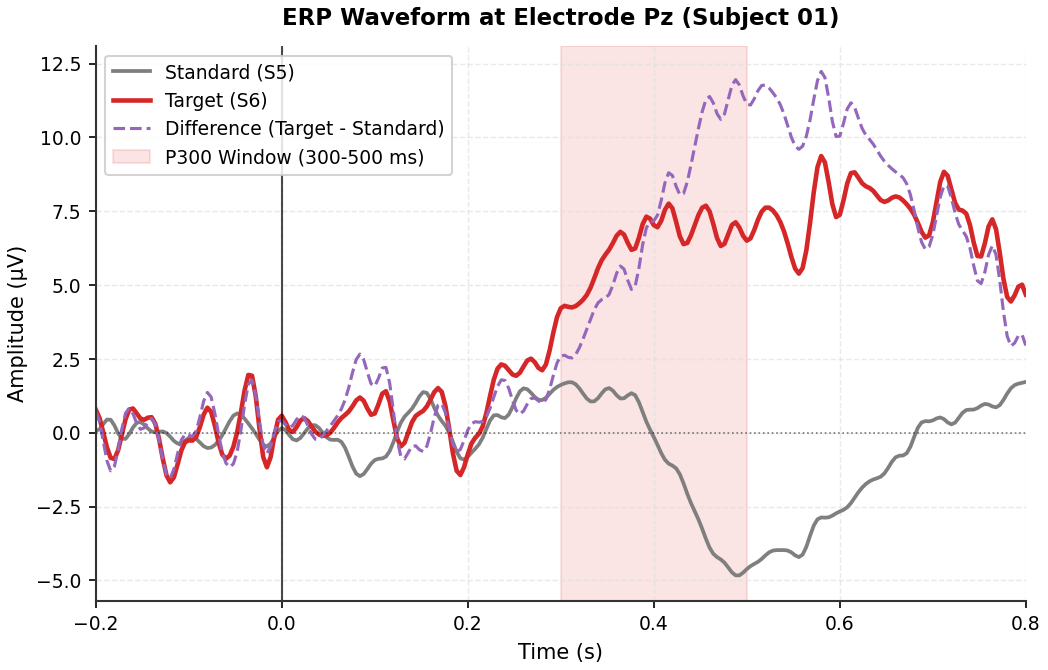

In [9]:
apply_style()

evoked_std = epochs["standard"].average()
evoked_tgt = epochs["target"].average()

times = evoked_std.times
ch_idx = evoked_std.ch_names.index("Pz") if "Pz" in evoked_std.ch_names else 0
pz_name = evoked_std.ch_names[ch_idx]

std_uv = evoked_std.data[ch_idx] * 1e6
tgt_uv = evoked_tgt.data[ch_idx] * 1e6
diff_uv = tgt_uv - std_uv

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(times, std_uv, label="Standard (S5)", color=COLORS["standard"], linewidth=1.8)
ax.plot(times, tgt_uv, label="Target (S6)", color=COLORS["target"], linewidth=2.2)
ax.plot(times, diff_uv, label="Difference (Target - Standard)", color=COLORS["difference"], linestyle="--", linewidth=1.5)

# Vùng P300 nổi bật
ax.axvspan(0.3, 0.5, color=COLORS["target"], alpha=0.12, label="P300 Window (300-500 ms)")
ax.axvline(0, color=COLORS["baseline"], linestyle="-", linewidth=1.0, alpha=0.7)
ax.axhline(0, color=COLORS["baseline"], linestyle=":", linewidth=0.8, alpha=0.5)

ax.set_title(f"ERP Waveform at Electrode {pz_name} (Subject 01)", pad=10)
ax.set_xlabel(LABELS["time"])
ax.set_ylabel(LABELS["amplitude"])
ax.set_xlim(TMIN, TMAX)
ax.legend(loc="upper left")

# Lưu hình chuẩn 300 DPI và vector PDF
save_figure(fig, "lab_chung_erp_pz", folder=FIGURES_DIR, save_pdf=True, close=False)
plt.show()

## 6. Huấn luyện thử mô hình LDA (Linear Discriminant Analysis)
Phân loại nhị phân giữa Target (1) và Standard (0) trên từng single-trial epoch bằng bộ phân loại tuyến tính LDA với 5-Fold Stratified Cross-Validation.

In [ ]:
binary_epochs = epochs["standard", "target"]
y = np.where(binary_epochs.events[:, -1] == event_id_mapped["target"], 1, 0)

# Ma trận đặc trưng: (n_epochs, n_channels, n_times) -> làm phẳng
X = binary_epochs.get_data(copy=True)
n_epochs, n_channels, n_times = X.shape
X_flat = X.reshape(n_epochs, n_channels * n_times)

print(f"Shape ma trận đầu vào X: {X_flat.shape}")
print(f"Tỉ lệ lớp: Target = {np.sum(y == 1)}, Standard = {np.sum(y == 0)}")

# Pipeline chuẩn hóa + LDA có shrinkage
clf = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

auc_scores = cross_val_score(clf, X_flat, y, cv=cv, scoring="roc_auc")
acc_scores = cross_val_score(clf, X_flat, y, cv=cv, scoring="balanced_accuracy")

print("=" * 50)
print(f"5-Fold CV ROC AUC:           {auc_scores.mean():.4f} ± {auc_scores.std():.4f}")
print(f"5-Fold CV Balanced Accuracy: {acc_scores.mean():.4f} ± {acc_scores.std():.4f}")
print("=" * 50)

Shape ma trận đầu vào X: (579, 31877)
Tỉ lệ lớp: Target = 81, Standard = 498
